# PR5: Data Preprocessing and EDA (Titanic dataset)

**Aim:** Clean the data, fill missing values, scale features, encode text columns and do basic statistics.

Steps in order: **Load -> Clean -> Missing values -> Encode -> Scale -> Statistics**

## 1. Load the dataset

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


## 2. Data cleaning

- Remove duplicate rows.
- Drop columns that are not useful: `PassengerId`, `Name`, `Ticket`, `Cabin` (Cabin has too many missing values).

In [4]:
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])
df.head()

Duplicates: 0


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


## 3. Missing value handling

In [5]:
print(df.isnull().sum())

Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64


- `Age` is a number, so fill with the **median**.
- `Embarked` is text, so fill with the **mode** (most common value).

In [6]:
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

print(df.isnull().sum())

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


## 4. Encoding (text to numbers)

- `Sex` has 2 values, so **label encoding** (male=0, female=1).
- `Embarked` has 3 values, so **one-hot encoding** (`get_dummies`).

In [7]:
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

df = pd.get_dummies(df, columns=["Embarked"], dtype=int)
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,0,1
1,1,1,1,38.0,1,0,71.2833,1,0,0
2,1,3,1,26.0,0,0,7.9250,0,0,1
3,1,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,0,35.0,0,0,8.0500,0,0,1


## 5. Feature scaling

- **Standardization:** (x - mean) / std. Result has mean 0 and std 1.
- **Min-Max scaling:** (x - min) / (max - min). Result is between 0 and 1.

In [8]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

cols = ["Age", "Fare"]

df_std = df.copy()
df_std[cols] = StandardScaler().fit_transform(df[cols])

df_mm = df.copy()
df_mm[cols] = MinMaxScaler().fit_transform(df[cols])

print("Standardized:")
print(df_std[cols].describe().loc[["mean", "std", "min", "max"]])
print()
print("Min-Max:")
print(df_mm[cols].describe().loc[["mean", "std", "min", "max"]])

Standardized:
               Age          Fare
mean  2.272780e-16  3.987333e-18
std   1.000562e+00  1.000562e+00
min  -2.224156e+00 -6.484217e-01
max   3.891554e+00  9.667167e+00

Min-Max:
           Age      Fare
mean  0.363679  0.062858
std   0.163605  0.096995
min   0.000000  0.000000
max   1.000000  1.000000


## 6. Statistical analysis

In [9]:
print(df.describe())

         Survived      Pclass         Sex         Age       SibSp       Parch  \
count  891.000000  891.000000  891.000000  891.000000  891.000000  891.000000   
mean     0.383838    2.308642    0.352413   29.361582    0.523008    0.381594   
std      0.486592    0.836071    0.477990   13.019697    1.102743    0.806057   
min      0.000000    1.000000    0.000000    0.420000    0.000000    0.000000   
25%      0.000000    2.000000    0.000000   22.000000    0.000000    0.000000   
50%      0.000000    3.000000    0.000000   28.000000    0.000000    0.000000   
75%      1.000000    3.000000    1.000000   35.000000    1.000000    0.000000   
max      1.000000    3.000000    1.000000   80.000000    8.000000    6.000000   

             Fare  Embarked_C  Embarked_Q  Embarked_S  
count  891.000000  891.000000  891.000000  891.000000  
mean    32.204208    0.188552    0.086420    0.725028  
std     49.693429    0.391372    0.281141    0.446751  
min      0.000000    0.000000    0.000000    0

In [10]:
print("Mean Age   :", df["Age"].mean())
print("Median Age :", df["Age"].median())
print("Mode Age   :", df["Age"].mode()[0])
print("Std of Fare:", df["Fare"].std())
print("Skewness of Fare:", df["Fare"].skew())

Mean Age   : 29.36158249158249
Median Age : 28.0
Mode Age   : 28.0
Std of Fare: 49.6934285971809
Skewness of Fare: 4.787316519674893


In [11]:
# Survival rate by group
print(df.groupby("Sex")["Survived"].mean())
print()
print(df.groupby("Pclass")["Survived"].mean())

Sex
0    0.188908
1    0.742038
Name: Survived, dtype: float64

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


Correlation: values near +1 or -1 mean a strong relationship.

In [12]:
corr = df.corr()
print(corr["Survived"].sort_values())

Pclass       -0.338481
Embarked_S   -0.149683
Age          -0.064910
SibSp        -0.035322
Embarked_Q    0.003650
Parch         0.081629
Embarked_C    0.168240
Fare          0.257307
Sex           0.543351
Survived      1.000000
Name: Survived, dtype: float64


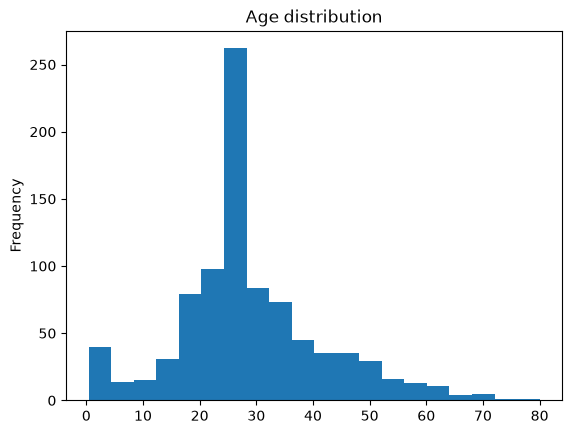

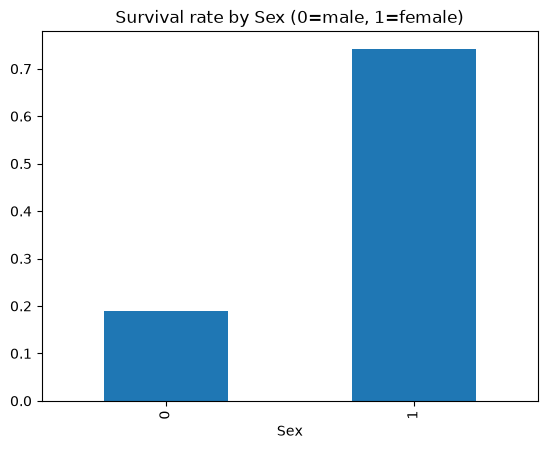

In [13]:
df["Age"].plot(kind="hist", bins=20, title="Age distribution")
plt.show()

df.groupby("Sex")["Survived"].mean().plot(kind="bar", title="Survival rate by Sex (0=male, 1=female)")
plt.show()

## Viva points

- **Median** is used for numeric gaps because it is not affected by outliers. **Mode** is used for text columns.
- **Label encoding** gives numbers 0,1,2... (fine for 2 categories). **One-hot** makes a separate 0/1 column per category (no false order).
- **Standardization** vs **Min-Max**: standardization is better when data has outliers.
- Scaling is needed for distance based models (KNN, SVM) and gradient based models.